<a href="https://colab.research.google.com/github/chisomomatthewmwambazi/retail-sales-analysis/blob/main/retail_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

file = "Retail_Sales_Data_2022-2024.xlsx"

orders = pd.read_excel(file, sheet_name="Orders")
customers = pd.read_excel(file, sheet_name="Customers")
products = pd.read_excel(file, sheet_name="Products")
stores = pd.read_excel(file, sheet_name="Stores")
returns = pd.read_excel(file, sheet_name="Returns")
calendar = pd.read_excel(file, sheet_name="Calendar")

orders.head()



,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Store ID,Product ID,Sales Channel,Quantity,Unit Price,Discount,Sales,Cost,Profit,Region
0,1,US-2022-100198,2022-01-01,2022-01-01,In-Store,CUS-18885,ST-116,FUR-CH-53642,In-Store,1,140.99,0.25,105.74,78.24,27.50,Central
1,2,US-2022-100200,2022-01-01,2022-01-01,In-Store,CUS-15566,ST-141,TEC-PH-39507,In-Store,2,89.99,0.05,170.98,141.76,29.22,East
2,3,US-2022-100200,2022-01-01,2022-01-01,In-Store,CUS-15566,ST-141,TEC-AC-68174,In-Store,6,36.99,0.10,199.75,151.08,48.67,East
3,4,US-2022-100200,2022-01-01,2022-01-01,In-Store,CUS-15566,ST-141,TEC-PR-84788,In-Store,1,129.99,0.20,103.99,91.17,12.82,East
4,5,US-2022-100200,2022-01-01,2022-01-01,In-Store,CUS-15566,ST-141,OFF-PA-36859,In-Store,9,13.79,0.00,124.11,56.25,67.86,East


In [2]:
print(orders.shape, customers.shape, products.shape)
print(stores.shape, returns.shape, calendar.shape)

(26385, 16) (3100, 7) (392, 7)
(48, 7) (1121, 6) (1096, 9)


In [3]:
df = orders.merge(products, on="Product ID", how="left")
df = df.merge(customers[["Customer ID", "Customer Name", "Segment"]], on="Customer ID", how="left")
df = df.merge(stores[["Store ID", "Store Name", "Store Type"]], on="Store ID", how="left")

print(df.shape)
df.isna().sum()

(26385, 26)


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Store ID,0
Product ID,0
Sales Channel,0
Quantity,0


1. Which categories make the most sales and profit?

In [4]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum().round(0)
cat["Profit Margin %"] = (cat["Profit"] / cat["Sales"] * 100).round(1)
cat.sort_values("Sales", ascending=False)

,Sales,Profit,Profit Margin %
Category,,,
Technology,1308903.0,266220.0,20.3
Office Supplies,873929.0,348316.0,39.9
Furniture,747436.0,269724.0,36.1


<Axes: title={'center': 'Total Sales by Category'}, xlabel='Category'>

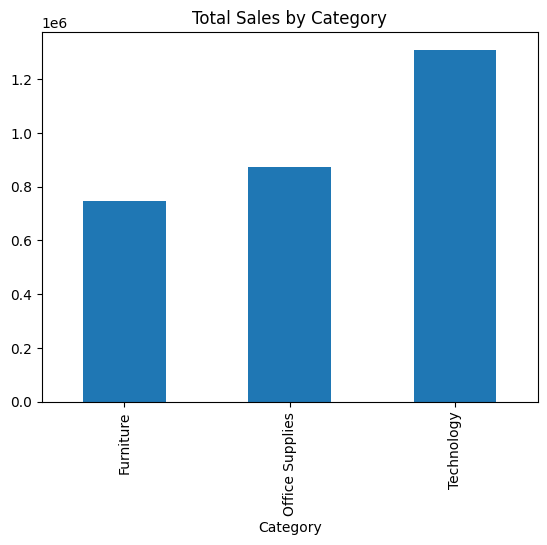

In [5]:
cat["Sales"].plot(kind="bar", title="Total Sales by Category")

Analysis: Technology brings in the most sales, and office supplies brings in the most profit

2. Which sub categories are the most and leadt profitable?

In [6]:
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().round(0)
sub["Profit Margin %"] = (sub["Profit"] / sub["Sales"] * 100).round(1)
sub.sort_values("Profit Margin %")

,Sales,Profit,Profit Margin %
Sub-Category,,,
Phones,140814.0,17817.0,12.7
Monitors,238144.0,35663.0,15.0
Copiers,204485.0,31602.0,15.5
Printers,324347.0,58507.0,18.0
Accessories,401113.0,122630.0,30.6
Appliances,232573.0,71398.0,30.7
Chairs,294228.0,104159.0,35.4
Tables,257624.0,91788.0,35.6
Bookcases,101852.0,37214.0,36.5


1. Which category brings in the most sales? Is it also the most profitable?
Accessories brings in the most sales (401k) and the most profitable (30.6%)

2. Is there a sub-category with high sales but a low margin?
Printers has the 2nd highest sales (324k), but one of the lowest profit margins with just (18%)

Sales and profit over time

<Axes: title={'center': 'Monthly Sales and Profit'}, xlabel='Year-Month'>

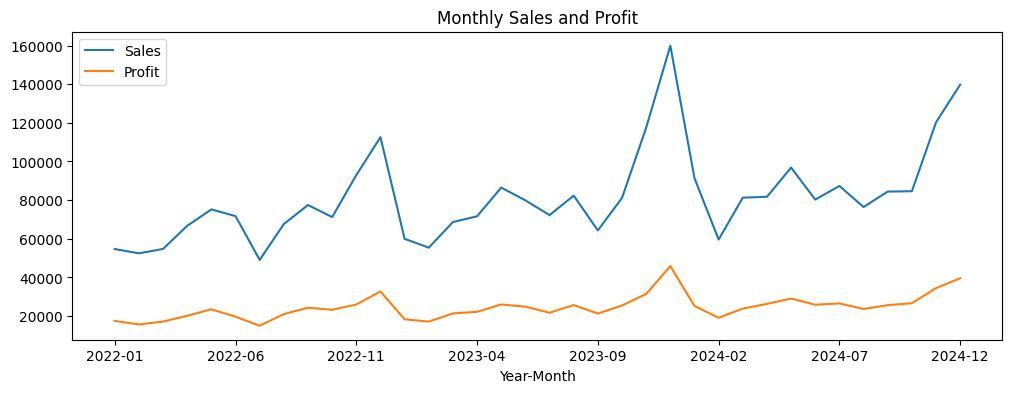

In [7]:
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
monthly = df.groupby("Year-Month")[["Sales", "Profit"]].sum()
monthly.plot(title="Monthly Sales and Profit", figsize=(12, 4))

Does discounting hurt profit?

In [8]:
disc = df.groupby("Discount")[["Sales", "Profit"]].sum()
disc["Margin %"] = (disc["Profit"] / disc["Sales"] * 100).round(1)
disc

,Sales,Profit,Margin %
Discount,,,
0.00,1356635.67,489976.48,36.1
0.05,334750.26,114541.61,34.2
0.10,410647.96,122311.35,29.8
0.15,245552.91,63491.81,25.9
0.20,300109.73,66057.13,22.0
0.25,123840.85,19154.36,15.5
0.30,125831.54,9983.11,7.9
0.40,32898.30,-1256.26,-3.8


Yes, discounting does hurt profit. We notice a trend as the discount increases, the profit margins begin to drop

## Conclusion

**Summary:** Across 2022-2024, the business made about 2.93M in sales and 0.88M in profit, an overall margin of roughly 30%. High sales do not always mean high profit.

**Key findings**

1. **Technology has the most sales but not the most profit.** It brings in about 1.31M, but Office Supplies is the most profitable category (about 348K profit, ~40% margin).
2. **Accessories is the strongest sub-category.** It has the highest sales (about 401K) and the highest profit (about 123K).
3. **Printers sell well but earn little per sale.** It has the 2nd highest sales (about 324K) but a margin of only 18%. Monitors (15%) and Phones (12.7%) have even lower margins.
4. **The highest-margin sub-categories are small ones.** Art and Labels have margins of about 48%, but they sell in lower volumes, so their total profit is modest.

**Recommendations**
- Promote Accessories and Office Supplies, which combine strong sales with strong margins.
- Review the pricing and costs of Printers, Monitors and Phones, because they sell well but keep little profit.
- Look into what is driving the low Technology margins before making changes.

**Limitations:** This analysis uses totals for one retailer over three years. It does not yet look at discounts, returns, time trends, or differences between stores and regions, so these findings are a starting point rather than the full picture.